# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import numpy as np

# Load dataset
df = pd.read_csv('../data/airbnb_london.csv')

print(f"Loaded: {len(df):,} listings")
print(df.describe().round(1))

# Cap price outliers at the 95th percentile
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95].copy()

print(f"\n95th percentile price cap: £{p95:.0f}")
print(f"Listings retained: {len(df_cap):,} of {len(df):,}")

print("\nPrice by room type:")
print(df_cap.groupby('room_type')['price'].describe().round(1))


Loaded: 2,500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  

95th percentile price cap: £373
Listings retained: 2,375 of 2,500

Price by room type:
               

In [ ]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('../data/airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


In [ ]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


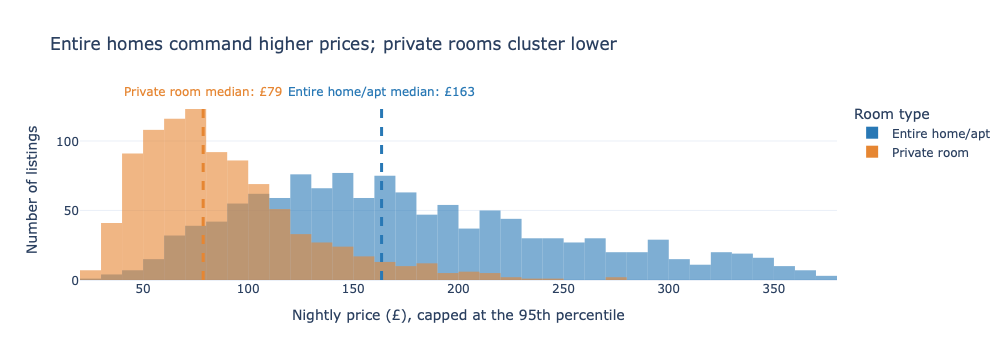

In [2]:

# Task 1: Overlapping price distributions

room_types = ['Entire home/apt', 'Private room']

hist_df = df_cap[
    df_cap['room_type'].isin(room_types)
].copy()

# Meaningful colours: entire homes in blue, private rooms in orange
room_colours = {
    'Entire home/apt': '#2878B5',
    'Private room': '#E68632'
}

fig1 = px.histogram(
    hist_df,
    x='price',
    color='room_type',
    barmode='overlay',
    opacity=0.6,
    nbins=50,
    color_discrete_map=room_colours,
    category_orders={'room_type': room_types},
    labels={
        'price': 'Nightly price (£)',
        'count': 'Number of listings',
        'room_type': 'Room type'
    },
    title='Entire homes command higher prices; private rooms cluster lower'
)

# Median reference lines and annotations for both room types
medians = hist_df.groupby('room_type')['price'].median()

for room_type in room_types:
    median_price = medians[room_type]
    colour = room_colours[room_type]

    fig1.add_vline(
        x=float(median_price),
        line_dash='dash',
        line_color=colour,
        line_width=3,
        annotation_text=f'{room_type} median: £{median_price:.0f}',
        annotation_position='top',
        annotation_font_color=colour
    )

fig1.update_layout(
    xaxis_title='Nightly price (£), capped at the 95th percentile',
    yaxis_title='Number of listings',
    legend_title='Room type',
    template='plotly_white'
)

fig1.show()


## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

Two busiest boroughs by median reviews per month:
neighbourhood
Tower Hamlets    1.75
Hackney          1.66
Name: reviews_per_month, dtype: float64


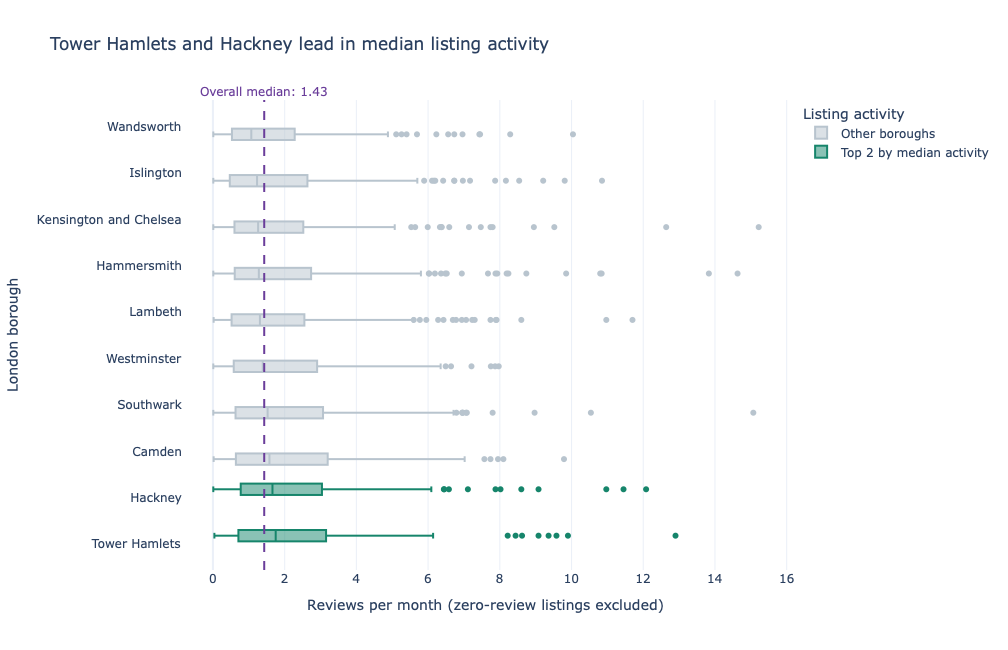

In [3]:

# Task 2: Listing activity by borough

# Find the borough/location column in the dataset
possible_borough_cols = [
    'borough',
    'neighbourhood',
    'neighbourhood_cleansed',
    'district'
]

borough_col = next(
    (col for col in possible_borough_cols if col in df.columns),
    None
)

if borough_col is None:
    raise ValueError(
        "Borough column not found. Available columns:\n"
        + ", ".join(df.columns)
    )

# Check required activity column
if 'reviews_per_month' not in df.columns:
    raise ValueError(
        "Column 'reviews_per_month' not found. "
        "Check df.columns for the correct column name."
    )

# Exclude missing, zero, and negative review activity
activity_df = df[
    df[borough_col].notna()
    & df['reviews_per_month'].notna()
    & (df['reviews_per_month'] > 0)
].copy()

# Calculate borough medians and sort from most to least active
borough_medians = (
    activity_df.groupby(borough_col)['reviews_per_month']
    .median()
    .sort_values(ascending=False)
)

top_two = borough_medians.head(2).index.tolist()

print("Two busiest boroughs by median reviews per month:")
print(borough_medians.head(2).round(2))

# Meaningful colour: green highlights the two most active boroughs
activity_df['activity_group'] = np.where(
    activity_df[borough_col].isin(top_two),
    'Top 2 by median activity',
    'Other boroughs'
)

activity_colours = {
    'Top 2 by median activity': '#16856B',
    'Other boroughs': '#B8C4CE'
}

# Sort categories so the most active borough appears at the top
borough_order = borough_medians.index.tolist()

fig2 = px.box(
    activity_df,
    x='reviews_per_month',
    y=borough_col,
    color='activity_group',
    color_discrete_map=activity_colours,
    category_orders={borough_col: borough_order[::-1]},
    points='outliers',
    orientation='h',
    hover_data=['reviews_per_month'],
    labels={
        'reviews_per_month': 'Reviews per month',
        borough_col: 'London borough',
        'activity_group': 'Activity group'
    },
    title=(
        f"{top_two[0]} and {top_two[1]} lead in median listing activity"
        if len(top_two) == 2
        else "Listing activity by borough"
    )
)

# Add an annotated reference line for the overall median
overall_median = activity_df['reviews_per_month'].median()

fig2.add_vline(
    x=float(overall_median),
    line_dash='dash',
    line_color='#6A3D9A',
    line_width=2,
    annotation_text=f'Overall median: {overall_median:.2f}',
    annotation_position='top',
    annotation_font_color='#6A3D9A'
)

fig2.update_layout(
    xaxis_title='Reviews per month (zero-review listings excluded)',
    yaxis_title='London borough',
    legend_title='Listing activity',
    template='plotly_white',
    height=max(650, 28 * len(borough_order))
)

fig2.show()

